# KAN on Buchwald-Hartwig amination with the Science 2018 DFT descriptors

**Source.** Ahneman, Estrada, Lin, Dreher, Doyle, *Science* **2018**, *360*, 186-190
(DOI 10.1126/science.aar5169). The DFT descriptor table is the one shipped with the `edbo`
package (`science_dft.csv`, 3955 reactions). The component names come from the authors' own
`rxnpredict` repository and are matched back onto the descriptor table in section 1.

**Reaction.** Pd-catalyzed C-N coupling of 15 aryl halides (five scaffolds as the chloride,
bromide and iodide) with 4-methylaniline, four biaryl phosphine ligands (XPhos, *t*-BuXPhos,
*t*-BuBrettPhos, AdBrettPhos), three organic bases (P2Et, BTMG, MTBD) and 22 isoxazole additives,
run in 1536-well plates.

**The paper's finding.** A random forest on these descriptors predicted yield far better than a
linear model, and the additive descriptors carried much of the signal. Follow-up experiments
showed the isoxazole additives can consume the Pd(0) catalyst by oxidative addition into the
N-O bond, so those descriptors are reporting catalyst poisoning rather than the desired coupling.

**Descriptors used here.** The first chemistry notebook in this series used 2D RDKit descriptors
and could not tell one descriptor of a component from another. This one uses the paper's DFT
descriptors, 24 of them chosen in advance to cover each component's electronics (HOMO, LUMO,
charges, NMR shifts), size (volume) and polarity (dipole). Collinearity inside a component
remains: four ligands and three bases cannot support more than three and two independent effects.

**Units.** The authors standardized `science_dft.csv` column by column, so every descriptor is in
standard deviations, not in ppm, hartree or cubic angstrom. Section 1 checks this. Curves in this
notebook are therefore read as "how the prediction moves per standard deviation of the
descriptor", and the component identities recovered below carry the chemistry.

**Target.** Yield in percent, regression. Success for the threshold rules: above 20 % yield.

## What this notebook does

Every dataset notebook in this series runs the same pipeline from `pycse.sklearn.kan_interpret`,
so the results are comparable across chemistries:

1. **Models on identical folds.** A linear baseline, random forest, gradient boosting and a KAN
   scored by 5x3 repeated cross-validation with the scaler refit inside each fold, and a paired
   Wilcoxon test of the KAN against the best other model.
2. **Single-descriptor thresholds.** Class-balanced stumps scored by balanced accuracy, with the
   majority baseline, so a "rule" that only predicts the majority class scores 0.5.
3. **Response curves that survive refitting.** Near-duplicate descriptors are pruned first, so
   an effect is not split between interchangeable columns. Each top descriptor then gets an
   accumulated local effect curve in its own units, with the linear baseline and the envelope
   of five refits, and the location of any step or window edge. A shape that changes from
   fold to fold is not a finding.
4. **A check against the known chemistry.** What the source paper established, or (for the
   synthetic benchmark) the generating equations, overlaid on what the pipeline recovered.

No emoji, no claims from a single fit.


In [1]:
import os

os.environ["JAX_PLATFORM_NAME"] = "cpu"
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
)
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score, accuracy_score

from pycse.sklearn.kan import KAN
from pycse.sklearn.kan_interpret import (
    accumulated_local_effects,
    accumulated_local_effects_cv,
    classify_shape,
    cv_compare,
    partial_effects,
    partial_effects_cv,
    plot_fold_scores,
    plot_partial_effect,
    prune_collinear,
    sensitivity,
    threshold_rules,
    transitions,
)
from pycse.sklearn._plotstyle import (
    INK_2,
    MUTED,
    BASELINE,
    SURFACE,
    SERIES,
    PX,
    style_axes,
    finish_axes,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Record the environment: KAN fits move slightly between jax/XLA builds.
import importlib.metadata as _md

print(
    "Versions:",
    ", ".join(
        f"{p} {_md.version(p)}" for p in ("pycse", "jax", "optax", "numpy", "scikit-learn", "scipy")
    ),
)


Versions: pycse 2.13.0, jax 0.12.0.1, optax 0.2.8, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1


## 1. Load the DFT descriptor table and recover the component names

The descriptor table has no names, but the authors published the per-molecule descriptor tables
and the name lists separately. Standardization is monotone per column, so the *k*-th smallest
value of a descriptor in the dataset belongs to the molecule with the *k*-th smallest value in the
per-molecule table. The mapping built from one descriptor is checked against two others: if it is
right, every reaction with molecule M's value of descriptor A also carries M's value of B.


In [2]:
URL = "https://raw.githubusercontent.com/b-shields/edbo/master/examples/DOE/data/aryl_amination/science_dft.csv"
RXN = "https://raw.githubusercontent.com/doylelab/rxnpredict/master/"
raw = pd.read_csv(URL)
CHOSEN = {
    "additive": [
        "additive_E_LUMO", "additive_E_HOMO", "additive_.C3_NMR_shift", "additive_.C4_NMR_shift",
        "additive_.C5_NMR_shift", "additive_.N1_electrostatic_charge", "additive_.O1_electrostatic_charge",
        "additive_dipole_moment", "additive_molecular_volume",
    ],
    "aryl halide": [
        "aryl_halide_E_LUMO", "aryl_halide_E_HOMO", "aryl_halide_.C1_NMR_shift",
        "aryl_halide_.C1_electrostatic_charge", "aryl_halide_.C4_NMR_shift", "aryl_halide_.H2_NMR_shift",
        "aryl_halide_dipole_moment", "aryl_halide_molecular_volume", "aryl_halide_hardness",
    ],
    "base": ["base_E_HOMO", "base_.N1_electrostatic_charge", "base_molecular_volume"],
    "ligand": ["ligand_.P1_electrostatic_charge", "ligand_dipole_moment", "ligand_.C1_NMR_shift"],
}  # fmt: skip
COMPONENT = {c: comp for comp, cols in CHOSEN.items() for c in cols}
X_df = raw[list(COMPONENT)].copy()
const = [c for c in X_df.columns if X_df[c].nunique() <= 1]
X_df = X_df.drop(columns=const)
print(f"Dropped constant descriptors: {const}")
y = raw["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 20.0).astype(int)
SUCCESS_RULE = "yield above 20 %"

stats = X_df.agg(["mean", "std"]).T
print(f"Descriptor means are {stats['mean'].abs().max():.3f} or less and standard deviations "
      f"{stats['std'].min():.3f} to {stats['std'].max():.3f}: the table is standardized.")  # fmt: skip


def recover_names(key_col, table_col, table, names, checks):
    """Map each dataset level of key_col to a molecule name, then verify on other descriptors."""
    rank = np.argsort(np.argsort(table[table_col].to_numpy()))
    levels = np.sort(raw[key_col].unique())
    assert len(levels) == len(table), f"{len(levels)} levels vs {len(table)} molecules"
    mapping = {i: levels[rank[i]] for i in range(len(table))}
    for s_col, t_col in checks:
        lv, rk = np.sort(raw[s_col].unique()), np.argsort(np.argsort(table[t_col].to_numpy()))
        for i in range(len(table)):
            seen = raw.loc[raw[key_col] == mapping[i], s_col].unique()
            assert len(seen) == 1 and np.isclose(seen[0], lv[rk[i]]), f"{t_col} disagrees for {names[i]}"
    return {mapping[i]: names[i] for i in range(len(table))}


def name_list(stem):
    n = pd.read_csv(RXN + f"smiles/{stem}-list.csv")
    return n["name"].tolist()[: len(pd.read_csv(RXN + f"R/{stem}.csv"))]



tables = {s: pd.read_csv(RXN + f"R/{s}.csv") for s in ["aryl_halide", "additive", "base", "ligand"]}
raw["aryl_halide"] = raw["aryl_halide_.C1_NMR_shift"].map(
    recover_names("aryl_halide_.C1_NMR_shift", "aryl_halide_*C1_NMR_shift", tables["aryl_halide"], name_list("aryl_halide"),
                  [("aryl_halide_.C4_NMR_shift", "aryl_halide_*C4_NMR_shift"), ("aryl_halide_E_LUMO", "aryl_halide_E_LUMO"),
                   ("aryl_halide_molecular_volume", "aryl_halide_molecular_volume")])
)  # fmt: skip
raw["additive"] = raw["additive_.C3_NMR_shift"].map(
    recover_names("additive_.C3_NMR_shift", "additive_*C3_NMR_shift", tables["additive"], name_list("additive"),
                  [("additive_.C4_NMR_shift", "additive_*C4_NMR_shift"), ("additive_E_LUMO", "additive_E_LUMO")])
)  # fmt: skip
raw["base"] = raw["base_E_HOMO"].map(
    recover_names("base_E_HOMO", "base_E_HOMO", tables["base"], name_list("base"),
                  [("base_molecular_volume", "base_molecular_volume"), ("base_.N1_electrostatic_charge", "base_*N1_electrostatic_charge")])
)  # fmt: skip
raw["ligand"] = raw["ligand_dipole_moment"].map(
    recover_names("ligand_dipole_moment", "ligand_dipole_moment", tables["ligand"], name_list("ligand"),
                  [("ligand_.C1_NMR_shift", "ligand_*C1_NMR_shift"), ("ligand_.P1_electrostatic_charge", "ligand_*P1_electrostatic_charge")])
)  # fmt: skip
raw["halide"] = np.select([raw.aryl_halide.str.contains("iodo"), raw.aryl_halide.str.contains("bromo")], ["I", "Br"], "Cl")

# The scaffold is the aryl halide without its halogen, keeping where the halogen was:
# 2- and 3-halopyridines are different substrates even though both lose a halogen to
# give pyridine. The names are written inconsistently ("1-ethyl-4-iodobenzene" but
# "1-bromo-4-ethylbenzene"), so the scaffold is read from the substituent named.


def scaffold_of(name):
    if "pyridine" in name:
        return f"pyridin-{name[0]}-yl"
    for key, label in [("trifluoromethyl", "4-(trifluoromethyl)phenyl"), ("methoxy", "4-methoxyphenyl"), ("ethyl", "4-ethylphenyl")]:
        if key in name:
            return label
    raise ValueError(name)


raw["scaffold"] = raw.aryl_halide.map(scaffold_of)
assert raw["scaffold"].nunique() == 5
print("Names recovered and verified against two further descriptors each.")
print(f"{len(raw)} reactions: {raw.aryl_halide.nunique()} aryl halides, {raw.additive.nunique()} additives, "
      f"{raw.base.nunique()} bases ({', '.join(sorted(raw.base.unique()))}), {raw.ligand.nunique()} ligands "
      f"({', '.join(sorted(raw.ligand.unique()))}).")  # fmt: skip

# Descriptors a published hypothesis names; kept first when duplicates are pruned.
HYPOTHESIS = []
HYPOTHESIS_CONTEXT = []

# For the new-molecule test: the molecule each reaction is grouped by.
GROUPS = raw["additive"].to_numpy()
GROUP_NAME = 'additive'


Dropped constant descriptors: []
Descriptor means are 0.025 or less and standard deviations 0.994 to 1.005: the table is standardized.


Names recovered and verified against two further descriptors each.
3955 reactions: 15 aryl halides, 22 additives, 3 bases (BTMG, MTBD, P2Et), 4 ligands (AdBrettPhos, XPhos, t-BuBrettPhos, t-BuXPhos).


3955 reactions, 24 descriptors. Target: yield (%) (regression).
Success for the threshold rules: yield above 20 % (59% of reactions).


,Component,Distinct,Min,Max
additive_E_LUMO,additive,22,-1.393,1.754
additive_E_HOMO,additive,22,-1.537,1.817
additive_.C3_NMR_shift,additive,22,-1.627,2.321
additive_.C4_NMR_shift,additive,22,-2.551,1.868
additive_.C5_NMR_shift,additive,20,-1.843,1.676
additive_.N1_electrostatic_charge,additive,22,-1.376,2.405
additive_.O1_electrostatic_charge,additive,19,-2.324,2.438
additive_dipole_moment,additive,22,-1.518,2.174
additive_molecular_volume,additive,22,-1.389,2.679
aryl_halide_E_LUMO,aryl halide,15,-3.705,0.531


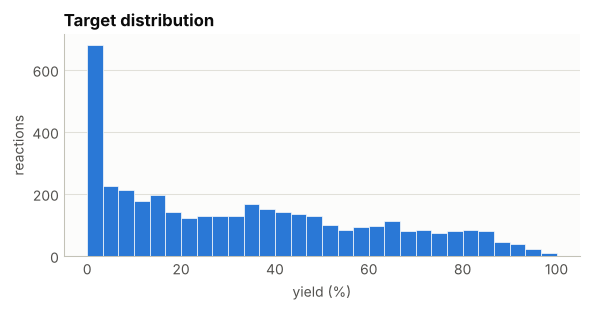

In [3]:
feature_names = list(X_df.columns)
X = X_df.to_numpy(dtype=float)
y = np.asarray(y, dtype=float)
SUCCESS = np.asarray(SUCCESS, dtype=int)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}

desc = pd.DataFrame(
    {
        "Component": [COMPONENT[f] for f in feature_names],
        "Distinct": X_df.nunique().values,
        "Min": X_df.min().values,
        "Max": X_df.max().values,
    },
    index=feature_names,
)
print(f"{len(X)} reactions, {n_features} descriptors. Target: {Y_LABEL} ({TASK}).")
print(f"Success for the threshold rules: {SUCCESS_RULE} ({SUCCESS.mean():.0%} of reactions).")
display(desc.round(3))

fig, ax = plt.subplots(figsize=(6, 3.2))
style_axes(ax)
if TASK == "regression":
    ax.hist(y, bins=30, color=SERIES[0], edgecolor=SURFACE, linewidth=0.5)
    finish_axes(ax, "Target distribution", Y_LABEL, "reactions")
else:
    vals, counts = np.unique(y, return_counts=True)
    ax.bar(vals, counts, width=0.6, color=[MUTED, SERIES[0]], linewidth=0)
    ax.set_xticks(vals)
    ax.set_xticklabels([f"{int(v)} ({c})" for v, c in zip(vals, counts)])
    finish_axes(ax, "Class balance", Y_LABEL, "reactions")
plt.tight_layout()
plt.show()


### 1.1 One descriptor per group of near-duplicates

Two descriptors that are near copies of each other (absolute correlation above 0.85) split one
effect between them arbitrarily, so a curve for either one is not identifiable. The pipeline
keeps the first descriptor of each group, the one the source paper names when there is one,
and drops the rest for every model.


In [4]:
PRUNE_R = 0.85
kept, dropped = prune_collinear(X, feature_names, PRUNE_R, keep_first=HYPOTHESIS)
for name, (partner, r) in dropped.items():
    print(f"dropped {name}: |r| = {r:.2f} with {partner}, which stays")
if not dropped:
    print(f"No pair of descriptors correlates above {PRUNE_R}; all {n_features} stay.")
X_df = X_df[kept]
feature_names = kept
X = X_df.to_numpy(dtype=float)
n_features = len(feature_names)
COMPONENTS = list(dict.fromkeys(COMPONENT[f] for f in feature_names))
COMP_COLOR = {c: SERIES[k % len(SERIES)] for k, c in enumerate(COMPONENTS)}
print(f"{n_features} descriptors go into every model.")


dropped aryl_halide_E_HOMO: |r| = 0.99 with aryl_halide_E_LUMO, which stays
dropped aryl_halide_hardness: |r| = 0.99 with aryl_halide_E_LUMO, which stays
dropped ligand_.C1_NMR_shift: |r| = 0.88 with ligand_dipole_moment, which stays
21 descriptors go into every model.


## 2. Models on identical folds

The four models see exactly the same 15 folds (5 splits x 3 repeats, scaler refit per fold).
The paired comparison asks a narrow question: on the same held-out reactions, is the KAN better
than the best of the other models, and how often?

The KAN carries light L1 and entropy penalties on its spline coefficients, at the same strength
(1e-3) in every notebook of the series. That strength was chosen once, on three of the datasets,
as the largest that cost no cross-validated accuracy: the benchmark stayed at R² 0.984, and the
deoxyfluorination and ligand sets improved. Ten times more cost accuracy on both regression sets.


Model                  r2               other
MLR                    0.375 ± 0.024   17.473 ± 0.368 (mae)
Random Forest          0.909 ± 0.014   5.528 ± 0.304 (mae)
Gradient Boosting      0.912 ± 0.007   5.929 ± 0.113 (mae)
KAN                    0.894 ± 0.013   6.602 ± 0.228 (mae)
KAN vs Gradient Boosting, paired over 15 folds: Δr2 = -0.0184 ± 0.0073, KAN better in 0/15, Wilcoxon p = 6.1e-05
(322 s)


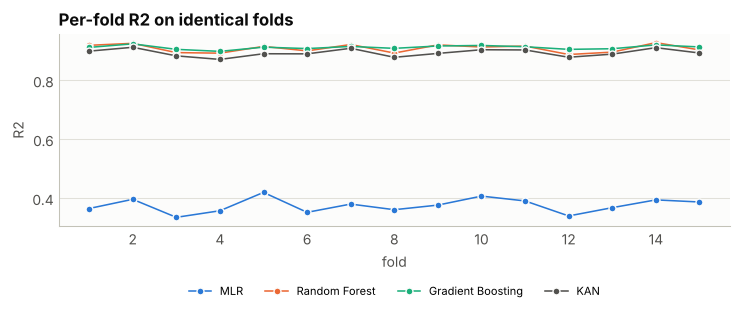

In [5]:
# One hidden layer; width 8 and 5 knots on datasets of 1000 reactions or more,
# 4 and 3 below that, so the spline count stays in proportion to the data.
WIDE = len(X) >= 1000
KAN_LAYERS = (n_features, 8 if WIDE else 4, 1)
KAN_GRID = 5 if WIDE else 3
KAN_REG = 1e-3  # L1 and entropy penalty on the spline coefficients
KAN_MAXITER = 300
CV_SPLITS, CV_REPEATS, CV_SEED = 5, 3, 42


def make_kan():
    return KAN(
        layers=KAN_LAYERS, grid_size=KAN_GRID, spline_order=3, l1_spline=KAN_REG, entropy_reg=KAN_REG
    )


def make_models():
    """Fresh models; the ensembles use the settings of the first two chemistry notebooks."""
    if TASK == "regression":
        return {
            "MLR": LinearRegression(),
            "Random Forest": RandomForestRegressor(
                n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
                random_state=42, n_jobs=-1,
            ),  # fmt: skip
            "Gradient Boosting": GradientBoostingRegressor(
                n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
                min_samples_leaf=3, subsample=0.8, random_state=42,
            ),  # fmt: skip
            "KAN": make_kan(),
        }
    return {
        "Logistic": LogisticRegression(max_iter=2000),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_split=5, min_samples_leaf=2,
            random_state=42, n_jobs=-1,
        ),  # fmt: skip
        "Gradient Boosting": GradientBoostingClassifier(
            n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
            min_samples_leaf=3, subsample=0.8, random_state=42,
        ),  # fmt: skip
        "KAN": make_kan(),
    }


BASELINE_NAME = "MLR" if TASK == "regression" else "Logistic"

t0 = time.time()
cv_result = cv_compare(
    make_models(),
    X,
    y,
    task=TASK,
    n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS,
    random_state=CV_SEED,
    fit_kwargs={"KAN": {"maxiter": KAN_MAXITER}},
    verbose=False,
)
print(cv_result)
print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_fold_scores(ax, cv_result)
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
plt.tight_layout()
plt.show()


Held-out split: 3164 train / 791 test


,Test R2,Test MAE
Model,,
MLR,0.365,18.141
Random Forest,0.919,5.254
Gradient Boosting,0.910,6.116
KAN,0.900,6.600


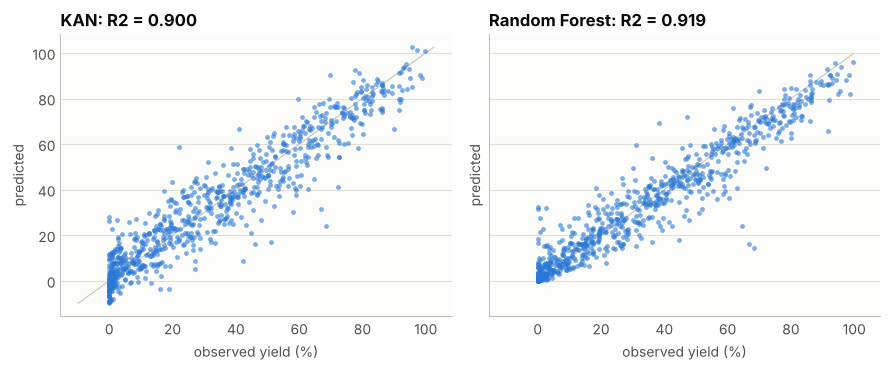

In [6]:
# One held-out split for the models the rest of the notebook interprets.
strat = y.astype(int) if TASK == "classification" else None
idx_tr, idx_te = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42, stratify=strat)
scaler = StandardScaler().fit(X[idx_tr])
X_tr, X_te = scaler.transform(X[idx_tr]), scaler.transform(X[idx_te])
y_tr, y_te = y[idx_tr], y[idx_te]

fitted, rows = {}, []
for name, model in make_models().items():
    if name == "KAN":
        model.fit(X_tr, y_tr, maxiter=KAN_MAXITER)
    else:
        model.fit(X_tr, y_tr.astype(int) if TASK == "classification" else y_tr)
    fitted[name] = model
    if TASK == "regression":
        p = model.predict(X_te)
        rows.append({"Model": name, "Test R2": r2_score(y_te, p), "Test MAE": mean_absolute_error(y_te, p)})
    else:
        p = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else np.clip(model.predict(X_te), 0, 1)
        rows.append({"Model": name, "Test AUC": roc_auc_score(y_te, p), "Test accuracy": accuracy_score(y_te, (p > 0.5).astype(int))})
kan, baseline = fitted["KAN"], fitted[BASELINE_NAME]


def model_means(labels, model=None):
    """Observed and predicted mean target per group, over the training reactions.

    A partial effect fixes the other descriptors at their mean, which is not a real
    compound; to compare a model with observed group means, average its predictions
    over the reactions that were actually run.
    """
    model = model or kan
    pred = np.ravel(model.predict(X_tr))
    lab = np.asarray(labels)[idx_tr]
    return (
        pd.DataFrame({"label": lab, "observed": y[idx_tr], "predicted": pred})
        .groupby("label")
        .agg(observed=("observed", "mean"), predicted=("predicted", "mean"), n=("observed", "size"))
    )
headline = pd.DataFrame(rows).set_index("Model")
print(f"Held-out split: {len(idx_tr)} train / {len(idx_te)} test")
display(headline.round(3))

# The KAN against the best other model on the held-out reactions
metric = "Test R2" if TASK == "regression" else "Test AUC"
best_other = headline.drop("KAN")[metric].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for ax, name in zip(axes, ["KAN", best_other]):
    style_axes(ax)
    m = fitted[name]
    if TASK == "regression":
        p = m.predict(X_te)
        lim = [min(y_te.min(), p.min()), max(y_te.max(), p.max())]
        ax.plot(lim, lim, color=BASELINE, linewidth=PX, zorder=1)
        ax.scatter(y_te, p, s=12, color=SERIES[0], alpha=0.6, linewidths=0, zorder=2)
        finish_axes(ax, f"{name}: R2 = {headline.loc[name, metric]:.3f}", f"observed {Y_LABEL}", "predicted")
    else:
        p = m.predict_proba(X_te)[:, 1] if hasattr(m, "predict_proba") else np.clip(m.predict(X_te), 0, 1)
        bins = np.linspace(0, 1, 21)
        ax.hist(p[y_te == 0], bins=bins, color=MUTED, alpha=0.7, label="observed 0", linewidth=0)
        ax.hist(p[y_te == 1], bins=bins, color=SERIES[0], alpha=0.7, label="observed 1", linewidth=0)
        ax.legend(frameon=False, fontsize=8)
        finish_axes(ax, f"{name}: AUC = {headline.loc[name, metric]:.3f}", "predicted probability", "reactions")
plt.tight_layout()
plt.show()


### 2.1 New molecules

The folds above split reactions at random, so almost every test reaction uses molecules the
models have already seen in other combinations. A chemist usually wants something harder: a
prediction for a molecule that was never run. Here every fold holds out whole molecules (named
below), three times with reshuffled groups, and the same four models are scored again, next to a model that knows nothing about the molecule
(the training mean, or the class prior). On held-out molecules that blank model is the line to clear.
R² can swing wildly when a held-out group has little spread of its own, so the mean absolute error
(or accuracy) is shown beside it.


Holding out whole additives: 22 of them, about a fifth per fold.


Model                  r2               other
Training mean          -0.064 ± 0.054   23.613 ± 1.125 (mae)
MLR                    0.111 ± 0.143   20.369 ± 1.440 (mae)
Random Forest          0.610 ± 0.123   11.169 ± 1.869 (mae)
Gradient Boosting      0.630 ± 0.125   11.414 ± 1.727 (mae)
KAN                    0.355 ± 0.143   16.729 ± 2.279 (mae)
KAN vs Gradient Boosting, paired over 15 folds: Δr2 = -0.2756 ± 0.1680, KAN better in 1/15, Wilcoxon p = 0.000122
(374 s)


,"random folds, r2","new additives, r2","random folds, mae","new additives, mae"
Training mean,NaN,-0.064,NaN,23.613
MLR,0.375,0.111,17.473,20.369
Random Forest,0.909,0.610,5.528,11.169
Gradient Boosting,0.912,0.630,5.929,11.414
KAN,0.894,0.355,6.602,16.729


Models that beat the training mean on new additives (R2): MLR, Random Forest, Gradient Boosting, KAN


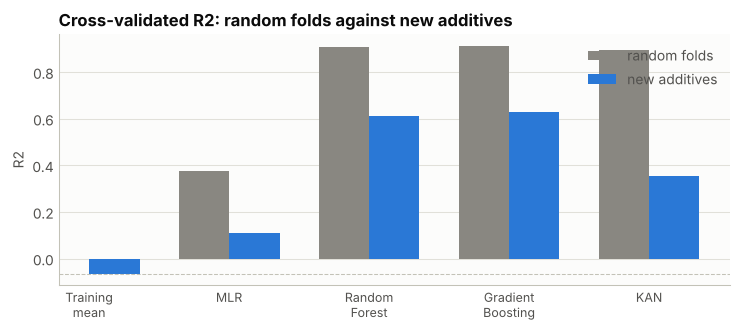

In [7]:
groups = np.asarray(GROUPS)
print(f"Holding out whole {GROUP_NAME}s: {len(np.unique(groups))} of them, about a fifth per fold.")
from sklearn.dummy import DummyClassifier, DummyRegressor

# A model that knows nothing about the molecule: the training mean, or the class prior.
# On held-out molecules it is the line every real model has to clear.
BLANK = "Training mean" if TASK == "regression" else "Class prior"
new_models = {BLANK: DummyRegressor() if TASK == "regression" else DummyClassifier(strategy="prior")}
new_models.update(make_models())
t0 = time.time()
new_result = cv_compare(
    new_models, X, y, task=TASK, n_splits=CV_SPLITS, n_repeats=CV_REPEATS,
    random_state=CV_SEED, fit_kwargs={"KAN": {"maxiter": KAN_MAXITER}}, groups=groups,
    verbose=False,
)  # fmt: skip
print(new_result)
print(f"({time.time() - t0:.0f} s)")
m = cv_result.metric
other = "mae" if TASK == "regression" else "accuracy"
both = pd.DataFrame(
    {
        f"random folds, {m}": cv_result.summary[m + "_mean"],
        f"new {GROUP_NAME}s, {m}": new_result.summary[m + "_mean"],
        f"random folds, {other}": cv_result.summary[other + "_mean"],
        f"new {GROUP_NAME}s, {other}": new_result.summary[other + "_mean"],
    },
    index=list(new_models),
)
display(both.round(3))
blank_score = new_result.summary.loc[BLANK, m + "_mean"]
clears = [n for n in make_models() if new_result.summary.loc[n, m + "_mean"] > blank_score]
print(f"Models that beat the {BLANK.lower()} on new {GROUP_NAME}s ({m.upper()}): {', '.join(clears) or 'none'}")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
style_axes(ax)
pos = np.arange(len(both))
ax.bar(pos - 0.18, both[f"random folds, {m}"], width=0.36, color=MUTED, linewidth=0, label="random folds")
ax.bar(pos + 0.18, both[f"new {GROUP_NAME}s, {m}"], width=0.36, color=SERIES[0], linewidth=0, label=f"new {GROUP_NAME}s")
ax.axhline(blank_score, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xticks(pos)
ax.set_xticklabels([n.replace(" ", "\n") for n in both.index], fontsize=9)
ax.legend(frameon=False, fontsize=8)
finish_axes(ax, f"Cross-validated {m.upper()}: random folds against new {GROUP_NAME}s", "", m.upper())
plt.tight_layout()
plt.show()


## 3. Single-descriptor thresholds

The Doyle and Sigman groups look for reactivity cliffs with one cut on one descriptor. The same
search here: a depth-1 tree with balanced class weights on each descriptor, scored on the held-out
reactions by balanced accuracy. A descriptor with no information scores 0.5 whatever the class
balance.


Majority-class accuracy on the test reactions: 0.592
Balanced-accuracy baseline for guessing: 0.500


,Feature,Threshold,Balanced_Acc,Accuracy,Precision,Recall
0,aryl_halide_.H2_NMR_shift,-0.693,0.707,0.697,0.800,0.650
1,aryl_halide_.C1_NMR_shift,0.416,0.667,0.633,0.825,0.483
2,aryl_halide_E_LUMO,0.419,0.659,0.707,0.689,0.919
3,aryl_halide_.C4_NMR_shift,-0.011,0.637,0.590,0.833,0.385
4,additive_.C3_NMR_shift,0.146,0.630,0.633,0.708,0.647
5,aryl_halide_molecular_volume,0.801,0.619,0.570,0.814,0.355
6,additive_.C4_NMR_shift,-0.037,0.612,0.625,0.684,0.679
7,aryl_halide_.C1_electrostatic_charge,0.810,0.606,0.547,0.853,0.284
8,aryl_halide_dipole_moment,0.958,0.606,0.547,0.853,0.284
9,additive_molecular_volume,-0.031,0.598,0.588,0.695,0.541


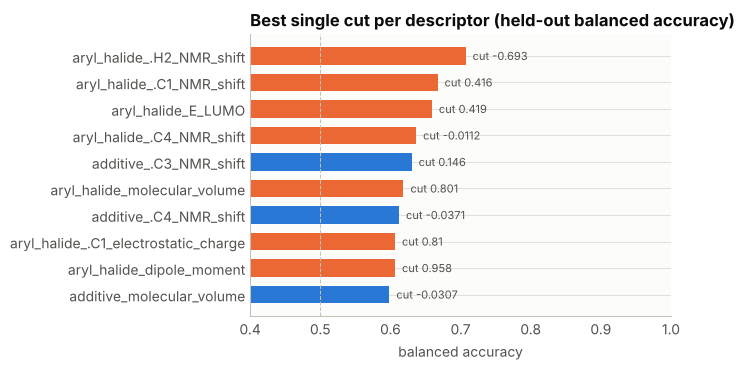

In [8]:
rules = threshold_rules(X[idx_tr], SUCCESS[idx_tr], feature_names, X[idx_te], SUCCESS[idx_te])
print(f"Majority-class accuracy on the test reactions: {rules.attrs['majority_accuracy']:.3f}")
print("Balanced-accuracy baseline for guessing: 0.500")
display(rules.head(10).round(3))

top = rules.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
style_axes(ax)
ax.barh(top.Feature, top.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top.Feature], height=0.65, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
for yk, (f, b, t) in enumerate(zip(top.Feature, top.Balanced_Acc, top.Threshold)):
    ax.text(b + 0.01, yk, f"cut {t:.3g}", va="center", fontsize=8, color=INK_2)
finish_axes(ax, "Best single cut per descriptor (held-out balanced accuracy)", "balanced accuracy", "")
plt.tight_layout()
plt.show()


## 4. Response curves, read as accumulated local effects

Sensitivity ranks the descriptors by how much the KAN prediction moves per standardized unit,
averaged over the training reactions. The top descriptors, among those with at least five
distinct values, then get a response curve in their own units.

The curve is an accumulated local effect rather than a partial effect. A partial effect holds
every other descriptor at its mean, which describes a compound that does not exist, and when
descriptors are correlated it asks the model about combinations it never saw. The accumulated
local effect moves a descriptor only within the reactions that already sit near each value and
adds up the local changes (Apley and Zhu, *J. R. Stat. Soc. B* 2020). The cell after the curves
puts the two readings side by side.

Each curve comes with the linear baseline read the same way, the envelope of five refits on
disjoint folds, and the observed values along the bottom. The curve is centred on the model's
mean prediction and adds up local changes, so at a sparsely sampled end it can leave the range of
the target: a probability curve that dips below zero there says "few reactions, still falling",
not that a probability is negative.


,Feature,Component,Sensitivity
0,aryl_halide_molecular_volume,aryl halide,87.9834
1,aryl_halide_dipole_moment,aryl halide,30.5988
2,aryl_halide_E_LUMO,aryl halide,30.2784
3,ligand_.P1_electrostatic_charge,ligand,25.6482
4,aryl_halide_.C1_electrostatic_charge,aryl halide,25.1561
5,aryl_halide_.H2_NMR_shift,aryl halide,13.2372
6,additive_.O1_electrostatic_charge,additive,12.4983
7,additive_E_LUMO,additive,12.0582
8,aryl_halide_.C1_NMR_shift,aryl halide,12.0339
9,additive_.N1_electrostatic_charge,additive,11.0016


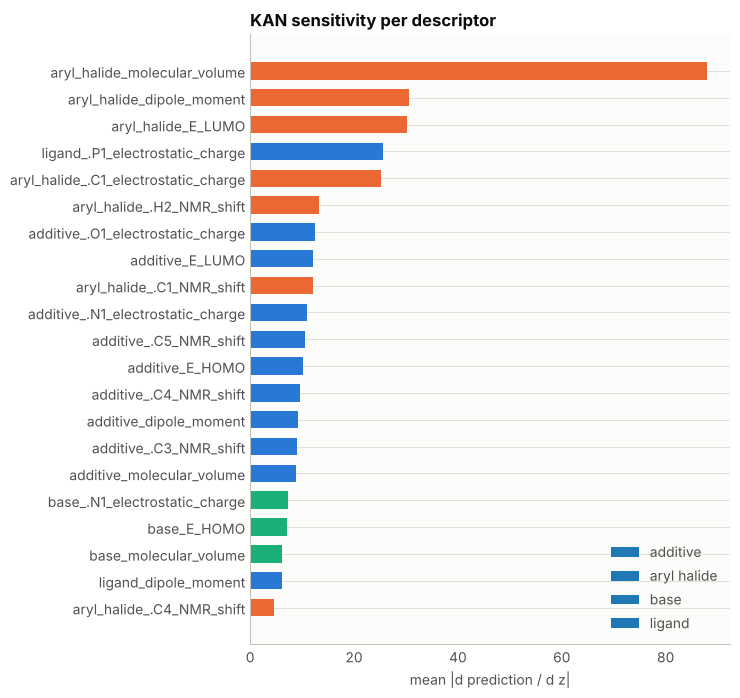

16 descriptors with at least 5 distinct values; 5 with fewer, shown as levels below.


curves and fold envelopes: 188 s


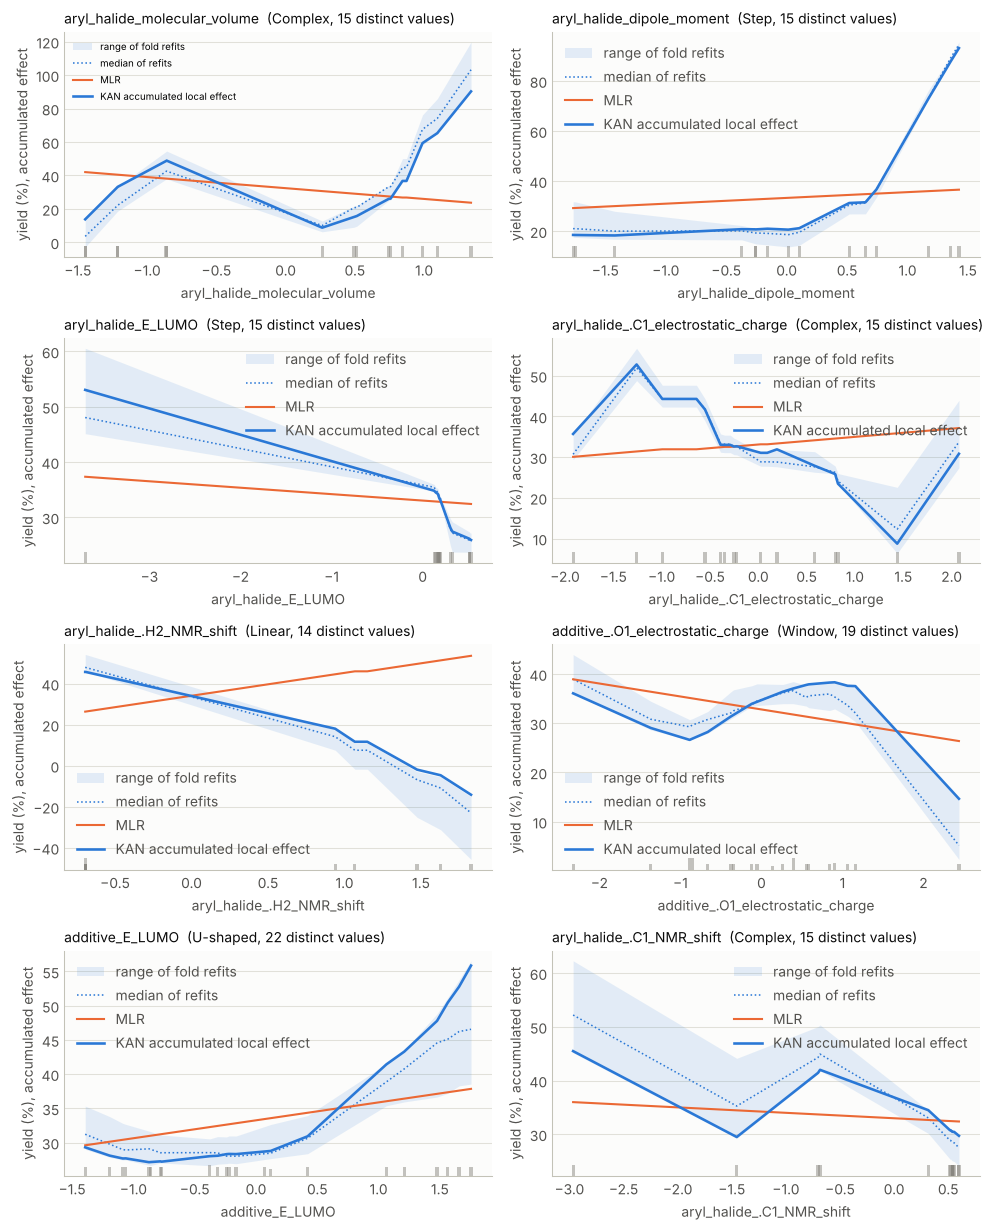

In [9]:
sens = sensitivity(kan, X_tr, task=TASK)
sens_df = pd.DataFrame(
    {"Feature": feature_names, "Component": [COMPONENT[f] for f in feature_names], "Sensitivity": sens}
).sort_values("Sensitivity", ascending=False).reset_index(drop=True)
display(sens_df.round(4))

fig, ax = plt.subplots(figsize=(7.5, 0.28 * n_features + 1.2))
style_axes(ax)
sd = sens_df.iloc[::-1]
ax.barh(sd.Feature, sd.Sensitivity, color=[COMP_COLOR[c] for c in sd.Component], height=0.65, linewidth=0)
for c in COMPONENTS:
    ax.barh([], [], color=COMP_COLOR[c], label=c)
ax.legend(frameon=False, fontsize=8, loc="lower right")
finish_axes(ax, "KAN sensitivity per descriptor", "mean |d prediction / d z|", "")
plt.tight_layout()
plt.show()

# A response curve needs values to interpolate between. Descriptors with fewer
# than five distinct values are handled as levels in a later cell instead.
MIN_LEVELS = 5
rich = [f for f in feature_names if X_df[f].nunique() >= MIN_LEVELS]
few = [f for f in feature_names if f not in rich]
top_features = sens_df[sens_df.Feature.isin(rich)].Feature.head(8).tolist()
TOP_K = len(top_features)
print(f"{len(rich)} descriptors with at least {MIN_LEVELS} distinct values; {len(few)} with fewer, shown as levels below.")
SHAPE_SCALE = y.std() if TASK == "regression" else 1.0
# An accumulated local effect is centred on the mean prediction and adds up local changes, so
# at a sparsely sampled end it can leave the range of the target (below 0 for a probability).
ALE_LABEL = f"{Y_LABEL}, accumulated effect"

t0 = time.time()
effects = accumulated_local_effects(
    kan, X, feature_names, top_features, scaler=scaler, task=TASK,
    extra_models={BASELINE_NAME: baseline},
)  # fmt: skip
effects = accumulated_local_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=effects, verbose=False,
)  # fmt: skip
print(f"curves and fold envelopes: {time.time() - t0:.0f} s")

ncol = 2
nrow = int(np.ceil(TOP_K / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 3.1 * nrow))
for ax, f in zip(np.ravel(axes), top_features):
    plot_partial_effect(ax, effects[f], ylabel=ALE_LABEL)
    label = effects[f].shape(scale=SHAPE_SCALE)[0]
    ax.set_title(f"{f}  ({label}, {effects[f].n_unique} distinct values)", loc="left", fontsize=10)
for ax in np.ravel(axes)[TOP_K:]:
    ax.axis("off")
np.ravel(axes)[0].legend(frameon=False, fontsize=7, loc="best")
plt.tight_layout()
plt.show()


,Feature,Partial effect,Refits agreeing (PE),Accumulated local effect,Refits agreeing (ALE)
0,aryl_halide_molecular_volume,Gap,0.8,Complex,1.0
1,aryl_halide_dipole_moment,Step,1.0,Step,1.0
2,aryl_halide_E_LUMO,Step,0.4,Step,1.0
3,aryl_halide_.C1_electrostatic_charge,Window,0.2,Complex,1.0
4,aryl_halide_.H2_NMR_shift,Step,0.4,Linear,1.0
5,additive_.O1_electrostatic_charge,Gap,0.2,Window,0.2
6,additive_E_LUMO,Step,0.4,U-shaped,0.8
7,aryl_halide_.C1_NMR_shift,Complex,0.6,Complex,0.6


Mean fraction of refits agreeing on the shape: partial effect 0.50, accumulated local effect 0.82


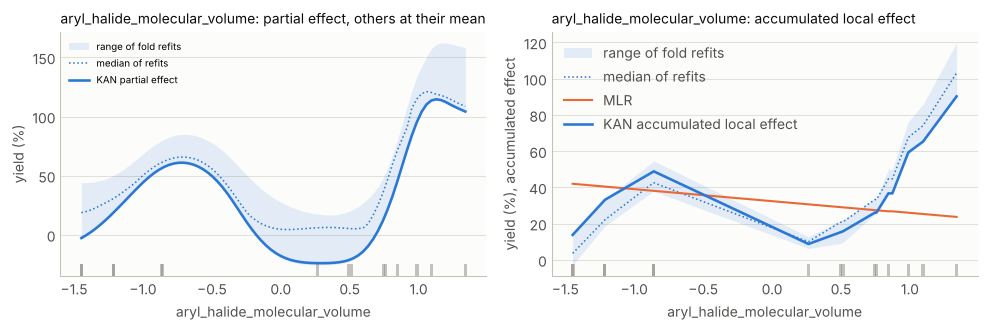

In [10]:
# The same KAN read both ways, with the same five refits behind each envelope.
pd_effects = partial_effects(kan, X, feature_names, top_features, scaler=scaler, task=TASK)
pd_effects = partial_effects_cv(
    make_kan, X, y, feature_names, top_features, task=TASK, n_splits=5, random_state=42,
    fit_kwargs={"maxiter": KAN_MAXITER}, effects=pd_effects, verbose=False,
)  # fmt: skip


def agreement(pe):
    """The full fit's shape label, and the fraction of refits that share it."""
    label = pe.shape(scale=SHAPE_SCALE)[0]
    folds = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
    return label, float(np.mean([lab == label for lab in folds]))


rows = []
for f in top_features:
    s_pe, a_pe = agreement(pd_effects[f])
    s_ale, a_ale = agreement(effects[f])
    rows.append(
        {
            "Feature": f,
            "Partial effect": s_pe,
            "Refits agreeing (PE)": a_pe,
            "Accumulated local effect": s_ale,
            "Refits agreeing (ALE)": a_ale,
        }
    )
reading_cmp = pd.DataFrame(rows)
display(reading_cmp.round(2))
print(
    f"Mean fraction of refits agreeing on the shape: partial effect "
    f"{reading_cmp['Refits agreeing (PE)'].mean():.2f}, accumulated local effect "
    f"{reading_cmp['Refits agreeing (ALE)'].mean():.2f}"
)

f0 = top_features[0]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
plot_partial_effect(axes[0], pd_effects[f0], ylabel=Y_LABEL)
plot_partial_effect(axes[1], effects[f0], ylabel=ALE_LABEL)
for ax, how in zip(axes, ["partial effect, others at their mean", "accumulated local effect"]):
    ax.set_title(f"{f0}: {how}", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()


In [11]:
# Descriptors with four or fewer levels. A response curve needs a grid; these get a
# table instead: the observed mean per level and the model's mean prediction over the
# same reactions (not at an averaged molecule, which is not a real compound).
if few:
    pred_tr = np.ravel(kan.predict(X_tr))
    rows = []
    for f in few:
        j = feature_names.index(f)
        for lvl in np.unique(X[:, j]):
            at = X[idx_tr, j] == lvl
            rows.append(
                {
                    "Feature": f,
                    "Component": COMPONENT[f],
                    "Level": lvl,
                    "Reactions": int((X[:, j] == lvl).sum()),
                    "Observed mean": float(y[X[:, j] == lvl].mean()),
                    "KAN mean prediction": float(pred_tr[at].mean()) if at.any() else np.nan,
                }
            )
    levels = pd.DataFrame(rows)
    display(levels.round(3))
    spread = levels.groupby("Feature")["Observed mean"].agg(lambda s: s.max() - s.min())
    print("Observed spread across the levels of each few-level descriptor:")
    print(spread.round(1).sort_values(ascending=False).to_string())
else:
    levels = pd.DataFrame()
    print("Every descriptor has at least five distinct values; nothing to show here.")


,Feature,Component,Level,Reactions,Observed mean,KAN mean prediction
0,base_E_HOMO,base,-1.247,1317,30.836,30.800
1,base_E_HOMO,base,0.046,1318,41.451,40.956
2,base_E_HOMO,base,1.201,1320,26.976,27.205
3,base_.N1_electrostatic_charge,base,-0.890,1317,30.836,30.800
4,base_.N1_electrostatic_charge,base,-0.507,1320,26.976,27.205
5,base_.N1_electrostatic_charge,base,1.397,1318,41.451,40.956
6,base_molecular_volume,base,-0.939,1318,41.451,40.956
7,base_molecular_volume,base,-0.446,1317,30.836,30.800
8,base_molecular_volume,base,1.385,1320,26.976,27.205
9,ligand_.P1_electrostatic_charge,ligand,-1.122,986,41.097,40.492


Observed spread across the levels of each few-level descriptor:
Feature
ligand_dipole_moment               20.9
ligand_.P1_electrostatic_charge    20.9
base_.N1_electrostatic_charge      14.5
base_molecular_volume              14.5
base_E_HOMO                        14.5


In [12]:
# Shape of the full fit, whether the five refits agree on it, and where its edges are.
# A curve whose range is under 5 % of the target's spread is "Constant" whatever its wiggles.
EDGED = {"Step", "Window", "Gap", "Saturating"}


def edge_range(values):
    values = [v for v in values if v is not None]
    if not values:
        return ""
    return f"{min(values):.3g} to {max(values):.3g} ({len(values)} of 5)"


def stability_table(effects):
    rows = []
    for f, pe in effects.items():
        label, _ = pe.shape(scale=SHAPE_SCALE)
        fold_labels = [classify_shape(pe.x_std, c, scale=SHAPE_SCALE)[0] for c in pe.curves]
        agree = float(np.mean([lab == label for lab in fold_labels]))
        width = float(np.mean(pe.hi - pe.lo) / (np.ptp(pe.median) + 1e-9))
        tr = transitions(pe.x_raw, pe.y)
        folds = [transitions(pe.x_raw, c) for c in pe.curves]
        edged = label in EDGED
        rows.append(
            {
                "Feature": f,
                "Component": COMPONENT[f],
                "Shape": label,
                "Nonlinearity": pe.nonlinearity(),
                "Fold agreement": agree,
                "Envelope / range": width,
                "Rise": tr["rise"] if edged else None,
                "Fall": tr["fall"] if edged else None,
                "Rise in refits": edge_range([t["rise"] for t in folds]) if edged else "",
                "Fall in refits": edge_range([t["fall"] for t in folds]) if edged else "",
                "Fold shapes": ", ".join(fold_labels),
            }
        )
    return pd.DataFrame(rows)


stab = stability_table(effects)
display(stab.round(3))
stable = stab[(stab["Fold agreement"] >= 0.8) & (stab["Envelope / range"] < 0.5)]
print("Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):")
for _, r in stable.iterrows():
    print(f"  {r.Feature}: {r.Shape}")
print("Shapes that do not:")
for _, r in stab.drop(stable.index).iterrows():
    print(f"  {r.Feature}: full fit {r.Shape}; refits {r['Fold shapes']}")


,Feature,Component,Shape,Nonlinearity,Fold agreement,Envelope / range,Rise,Fall,Rise in refits,Fall in refits,Fold shapes
0,aryl_halide_molecular_volume,aryl halide,Complex,0.918,1.0,0.150,NaN,NaN,,,"Complex, Complex, Complex, Complex, Complex"
1,aryl_halide_dipole_moment,aryl halide,Step,0.644,1.0,0.088,0.968,NaN,0.928 to 0.984 (5 of 5),,"Step, Step, Step, Step, Step"
2,aryl_halide_E_LUMO,aryl halide,Step,0.422,1.0,0.128,NaN,-0.854,,-0.859 to -0.0511 (5 of 5),"Step, Step, Step, Step, Step"
3,aryl_halide_.C1_electrostatic_charge,aryl halide,Complex,0.695,1.0,0.146,NaN,NaN,,,"Complex, Complex, Complex, Complex, Complex"
4,aryl_halide_.H2_NMR_shift,aryl halide,Linear,0.129,1.0,0.170,NaN,NaN,,,"Linear, Linear, Linear, Linear, Linear"
5,additive_.O1_electrostatic_charge,additive,Window,0.999,0.2,0.166,-0.267,1.777,-0.209 to -0.209 (1 of 5),1.46 to 1.78 (5 of 5),"Window, Complex, Complex, Complex, Complex"
6,additive_E_LUMO,additive,U-shaped,0.403,0.8,0.372,NaN,NaN,,,"U-shaped, U-shaped, U-shaped, Linear, U-shaped"
7,aryl_halide_.C1_NMR_shift,aryl halide,Complex,0.650,0.6,0.285,NaN,NaN,,,"Complex, Step, Complex, Complex, Saturating"


Shapes that survive refitting (4/5 folds agree, refits disagree by less than half the curve range):
  aryl_halide_molecular_volume: Complex
  aryl_halide_dipole_moment: Step
  aryl_halide_E_LUMO: Step
  aryl_halide_.C1_electrostatic_charge: Complex
  aryl_halide_.H2_NMR_shift: Linear
  additive_E_LUMO: U-shaped
Shapes that do not:
  additive_.O1_electrostatic_charge: full fit Window; refits Window, Complex, Complex, Complex, Complex
  aryl_halide_.C1_NMR_shift: full fit Complex; refits Complex, Step, Complex, Complex, Saturating


## 5. Check against the chemistry

With the names recovered, two things can be checked that no model is needed for. Oxidative
addition of Pd(0) into a carbon-halogen bond goes I > Br > Cl, so the same scaffold should give
higher yields as the halide gets heavier. And the paper's additive effect is catalyst poisoning,
so the additive ranking is a property of the isoxazole, not of the coupling partners.


,mean,count
halide,,
I,45.7,1318
Br,38.4,1319
Cl,15.1,1318


Mean yield per scaffold and halide (every row should rise left to right):


halide,Cl,Br,I
scaffold,,,
4-(trifluoromethyl)phenyl,12.5,26.9,33.7
4-ethylphenyl,3.9,43.5,52.6
4-methoxyphenyl,1.9,25.9,32.5
pyridin-2-yl,43.5,52.4,58.6
pyridin-3-yl,13.8,43.0,51.3


Scaffolds with Cl < Br: 5/5; with Br < I: 5/5


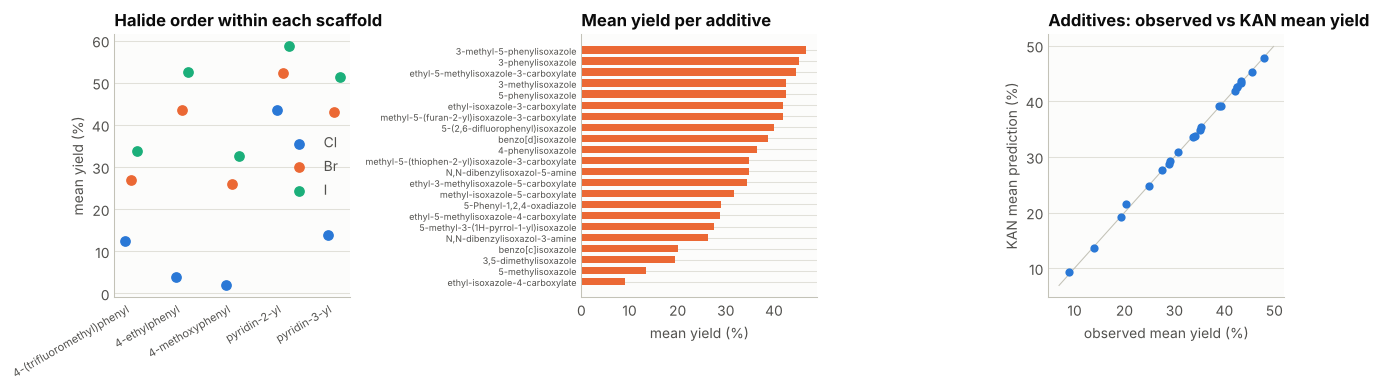

Spearman correlation of additive mean yield with the C3 shift: 0.67
The KAN reproduces the 22 additive means to a mean absolute error of 0.2 points.
Mean yield by ligand and base:


base,BTMG,MTBD,P2Et
ligand,,,
AdBrettPhos,29.2,44.4,27.0
XPhos,19.4,22.2,18.9
t-BuBrettPhos,35.2,47.9,29.6
t-BuXPhos,39.6,51.3,32.4


In [13]:
order = raw.groupby("halide")["yield"].agg(["mean", "count"]).reindex(["I", "Br", "Cl"]).round(1)
display(order)
piv = raw.pivot_table(index="scaffold", columns="halide", values="yield", aggfunc="mean")[["Cl", "Br", "I"]].round(1)
print("Mean yield per scaffold and halide (every row should rise left to right):")
display(piv)
print(f"Scaffolds with Cl < Br: {(piv.Cl < piv.Br).sum()}/{len(piv)}; with Br < I: {(piv.Br < piv['I']).sum()}/{len(piv)}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
ax = axes[0]
style_axes(ax)
for k, h in enumerate(["Cl", "Br", "I"]):
    ax.scatter(np.arange(len(piv)) + 0.12 * (k - 1), piv[h], s=45, color=SERIES[k], label=h, zorder=3)
ax.set_xticks(np.arange(len(piv)))
ax.set_xticklabels(piv.index, rotation=30, ha="right", fontsize=8)
ax.legend(frameon=False, fontsize=8, title=None)
finish_axes(ax, "Halide order within each scaffold", "", "mean yield (%)")

ax = axes[1]
style_axes(ax)
add = raw.groupby("additive").agg(x=("additive_.C3_NMR_shift", "first"), m=("yield", "mean")).sort_values("m")
ax.barh(np.arange(len(add)), add.m, color=SERIES[1], height=0.7, linewidth=0)
ax.set_yticks(np.arange(len(add)))
ax.set_yticklabels(add.index, fontsize=6.5)
finish_axes(ax, "Mean yield per additive", "mean yield (%)", "")

ax = axes[2]
style_axes(ax)
mm = model_means(raw.additive).join(add.x.rename("C3_shift"))
lim = [min(mm.observed.min(), mm.predicted.min()) - 2, max(mm.observed.max(), mm.predicted.max()) + 2]
ax.plot(lim, lim, color=BASELINE, linewidth=PX, zorder=1)
ax.scatter(mm.observed, mm.predicted, s=35, color=SERIES[0], linewidths=0, zorder=3)
finish_axes(ax, "Additives: observed vs KAN mean yield", "observed mean yield (%)", "KAN mean prediction (%)")
plt.tight_layout()
plt.show()

print(f"Spearman correlation of additive mean yield with the C3 shift: {add.m.corr(add.x, method='spearman'):.2f}")
print(f"The KAN reproduces the 22 additive means to a mean absolute error of {np.abs(mm.observed - mm.predicted).mean():.1f} points.")
print("Mean yield by ligand and base:")
display(raw.pivot_table(index="ligand", columns="base", values="yield", aggfunc="mean").round(1))


### Reading

The named data give the halide order exactly. The KAN, read properly, adds one thing the order does
not: the position of the halogen on the pyridine ring.

**The halide order is exact.** Mean yield is 45.7 % for the iodides, 38.4 % for the bromides and
15.1 % for the chlorides, and within every one of the five scaffolds yield rises from chloride to
bromide to iodide without exception. That is the oxidative addition reactivity order, across 3955
reactions.

**2-Halopyridines stand apart, and a stable curve finds them.** The aryl halide dipole moment
gives a step in all five refits, with its edge between 0.93 and 0.98 standard deviations. Above
it sit exactly the three 2-halopyridines, averaging 51.5 % against 28.5 % for the other twelve
substrates. The contrast is sharpest among the chlorides: 2-chloropyridine gives 43.5 %, while
3-chloropyridine gives 13.8 % and the three chlorobenzenes 1.9 to 12.5 %. That is consistent with
the known activation, toward oxidative addition, of a carbon-halogen bond next to the ring
nitrogen. The dipole is a proxy here: it is what separates 2-pyridyl from 3-pyridyl in this table.

**A stable edge can still rest on one molecule.** The aryl halide LUMO also gives a step in all
five refits, but every substrate sits between 0.13 and 0.53 standard deviations except
4-bromoanisole, at -3.7. The step is that one compound, and the refits place its edge anywhere in
the empty gap. Agreement between refits says the model is consistent, not that the data cover the
curve; the observed values along the bottom of each plot are there for this reason.

**The additives span 9 to 47 %.** The worst are ethyl-isoxazole-4-carboxylate (9.0 %),
5-methylisoxazole (13.4 %) and 3,5-dimethylisoxazole (19.4 %); the best are 3-methyl-5-phenyl-
isoxazole (46.7 %) and 3-phenylisoxazole (45.3 %). The additive mean yield correlates with the C3
NMR shift at Spearman 0.67, and the KAN reproduces all 22 additive means to a mean absolute error
of 0.2 points. The additive LUMO curve is U-shaped in four of five refits: the three worst
additives sit in the middle of the LUMO range, but so do some of the best, so it is a weak trend
over 22 molecules. The paper traced the additive effect to Pd insertion into the isoxazole N-O
bond, which consumes the catalyst.

**Pruning cannot fix three molecules.** It drops three near-duplicates, among them the aryl
halide HOMO and hardness (both correlate with the LUMO at 0.99). Three base descriptors survive
it, yet each one reproduces the same three group means, 41.5, 30.8 and 27.0 %, because each is a
relabelling of the same three bases. A component with three members has three numbers to give.

**The reading matters here.** Over the top eight descriptors, the refits agree on the shape 82 %
of the time read as accumulated local effects, against 50 % read as partial effects.

**Models.** Gradient boosting and the random forest reach cross-validated R² 0.912 and 0.909,
against 0.894 for the KAN and 0.375 for the linear model; the KAN loses in 15 folds of 15. The
gap between the linear model and the rest is the paper's finding: yield is not additive in these
descriptors. All descriptor values here are in standard deviations, because the authors
standardized the published table.

**On a new additive the KAN is the weakest of the three flexible models.** Holding out whole
additives, four or five of the 22 per fold, gradient boosting keeps an R² of 0.630 and the random
forest 0.610, against 0.355 for the KAN and 0.111 for the linear model; the training mean scores
-0.064. The KAN beats gradient boosting in 1 fold of 15. Every model clears the know-nothing line,
so the descriptors carry some information about an unseen isoxazole, but a third of the R² of about 0.9 on
random folds comes from recognising additives the models have already seen. The KAN's additive
curves describe these 22 molecules, not isoxazoles in general.


## 6. Summary dashboard

Four tiles, all from the numbers above: cross-validated score per model, the best single cuts,
the sensitivity grouped by reaction component, and the stability of the top response curves.


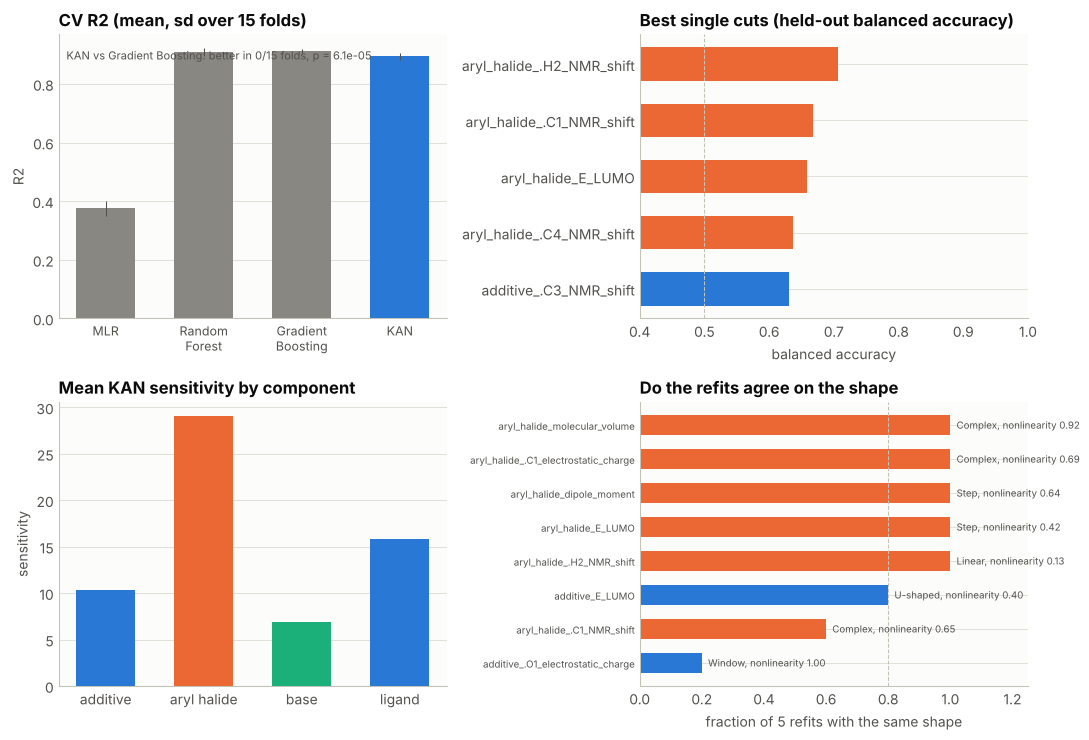

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
ax = axes[0, 0]
style_axes(ax)
s = cv_result.summary
names = list(s.index)
ax.bar(names, s[cv_result.metric + "_mean"], yerr=s[cv_result.metric + "_std"], color=[MUTED] * (len(names) - 1) + [SERIES[0]], width=0.6, linewidth=0, error_kw={"elinewidth": PX, "ecolor": INK_2})
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace(" ", "\n") for n in names], fontsize=9)
p = cv_result.pairwise
finish_axes(ax, f"CV {cv_result.metric.upper()} (mean, sd over {CV_SPLITS * CV_REPEATS} folds)", "", cv_result.metric.upper())
ax.text(0.02, 0.95, f"KAN vs {p['vs']}: better in {p['wins']}/{p['n']} folds, p = {p['p']:.2g}", transform=ax.transAxes, va="top", fontsize=8, color=INK_2)

ax = axes[0, 1]
style_axes(ax)
top5 = rules.head(5).iloc[::-1]
ax.barh(top5.Feature, top5.Balanced_Acc, color=[COMP_COLOR[COMPONENT[f]] for f in top5.Feature], height=0.6, linewidth=0)
ax.axvline(0.5, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0.4, 1.0)
finish_axes(ax, "Best single cuts (held-out balanced accuracy)", "balanced accuracy", "")

ax = axes[1, 0]
style_axes(ax)
comp_sens = sens_df.groupby("Component")["Sensitivity"].mean().reindex(COMPONENTS)
ax.bar(comp_sens.index, comp_sens.values, color=[COMP_COLOR[c] for c in comp_sens.index], width=0.6, linewidth=0)
finish_axes(ax, "Mean KAN sensitivity by component", "", "sensitivity")

ax = axes[1, 1]
style_axes(ax)
st = stab.sort_values(["Fold agreement", "Nonlinearity"])
ax.barh(st.Feature, st["Fold agreement"], color=[COMP_COLOR[c] for c in st.Component], height=0.6, linewidth=0)
ax.axvline(0.8, color=BASELINE, linewidth=PX, linestyle="--")
ax.set_xlim(0, 1.25)
for yk, (a, nl, sh) in enumerate(zip(st["Fold agreement"], st["Nonlinearity"], st.Shape)):
    ax.text(a + 0.02, yk, f"{sh}, nonlinearity {nl:.2f}", va="center", fontsize=7, color=INK_2)
ax.tick_params(axis="y", labelsize=7)
finish_axes(ax, "Do the refits agree on the shape", "fraction of 5 refits with the same shape", "")
plt.tight_layout()
plt.show()
